# Figure 3: Measuring the bound

How the decision bound is measured directly from each trial, how those direct
measures relate to the stopping model's fitted bound, and what the model says
about the bound and about the sources of commitments. Main figure: OL, low-SNR
block 2 (raw block numbering; coin-penalty condition). Rebuilt 2026-10-11 for
the stopping model (`pigeon.stopping`); the previous version (per-trial bound
slopes vs. DT and Δbound regressions) is backed up in
`../Figures/backup_2026-10-11_stoppingModel/`.

**Panels**

- **A. Direct measure and model bound, one trial.** The pigeon's position over
  the trial, the key press, the NDT period, and the direct bound estimate
  (`get_bounds`: the midpoint of the positions at DT − 1 and DT, the step the
  subject is inferred to have committed at). Behind it, that subject's fitted
  mean bound (knee form: high at step 1, falling to the **bound plateau** at the
  knee, then a slow decline) with the interquartile range of the trial-to-trial
  bound variability.
- **B. Example subject.** Per-trial measured |bound| vs. DT; the model's
  prediction for the *measured* bound (each subject simulated from their fit
  and run through the same `get_bounds` pipeline); and the model's actual bound
  at that step.
- **C. All subjects.** Z-scored measured |bound| vs. DT, data and model
  (simulated, measured the same way). DT = 1 is shown (normally excluded by
  the DT ≥ 2 filter, dotted line).
- **D. Plateau vs. direct measure.** Per subject: the median measured |bound|
  (raw positions, the standard trial filter) against the fitted plateau, for
  the data and for the model's simulated data.
- **E. Plateaus across blocks.** Fitted plateau per subject in all six OL
  blocks (low and high SNR × three reward conditions).
- **F. Sources of commitments.** From the simulated data (where each commit's
  source is known): bound crossings, guesses (including start-frame guesses)
  and anticipations, on all trials and on trials passing the standard filter;
  hatching marks lapses (random choice).

**Data.** Trials from `get_stopping_model_trials('OL', 1–6)` (the trials the
model was fit to: trial_number ≥ max(10, ceil(τ)), recorded choice; raw
positions, no bias correction). Direct measures (B–D) additionally use the
standard filter `get_good_trial_array` (DT ≥ 2, or ≥ 1 in C; no wall hit; RT
cutoff). Fits: `data/processed/stopping_fits_main.pkl` (from
`scripts/run_stopping_fits.py`).

In [1]:
import sys
sys.path.insert(0, '..')

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import scipy.stats

from pigeon.data import get_good_trial_array
from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label
from pigeon.stopping import (bound_time_course, get_stopping_model_trials, infer_bounds_like_data,
                             simulate_stopping_data_table)

PROCESSED = Path('../data/processed')

## Data, fits and simulated data

Each subject's trials (all six OL blocks, so that `get_bounds`' per-subject NDT
estimate and RT cutoffs see the same trials as for the real data) are
simulated `SIM_REPS` times from the subject's fitted parameters, then run
through the real-data bound pipeline (`infer_bounds_like_data`). Simulated
trials take `trial_number = 99`: they replace trials that already passed the
trial-number and adaptation exclusions.

In [2]:
BLOCK = 'B2'          # raw OL block 2: low SNR, coin penalty
EXAMPLE_SUBJECT = 16
SIM_REPS = 10
SIM_SEED = 3
DTS = np.arange(1, 11)

trials = get_stopping_model_trials('OL', [1, 2, 3, 4, 5, 6])
fits = pd.read_pickle(PROCESSED / 'stopping_fits_main.pkl')
fits = fits[fits.task == 'OL']
sim = simulate_stopping_data_table(trials, fits, group_col='condition', num_reps=SIM_REPS,
                                   rng=np.random.default_rng(SIM_SEED))
sim = infer_bounds_like_data(sim).assign(trial_number=99)

real_b, sim_b = trials[trials.condition == BLOCK], sim[sim.condition == BLOCK]
fits_b = fits[fits.group == BLOCK].set_index('subject_index')
print(f'{BLOCK}: {len(real_b):,} real trials, {len(sim_b):,} simulated ({SIM_REPS} per real trial), '
      f'{len(fits_b)} subjects')

OL: subjects with a good adaptation tau fit, by block: {1: 2, 2: 25, 3: 9, 4: 18, 5: 8, 6: 9}
OL: 42,252 trials in blocks [1, 2, 3, 4, 5, 6]; excluded 3,240 with trial_number < 10, 225 more in the adaptation transient, 364 more with no choice; 60 subjects


B2: 4,599 real trials, 45,990 simulated (10 per real trial), 60 subjects


## Panel statistics

- **C:** per subject, |bound| is z-scored over that subject's trials passing the
  filter (DT ≥ 1, DT ≤ 10), then averaged per DT; subjects with < 5 trials are
  skipped (reported).
- **D:** median |bound| per subject over trials passing the standard filter
  with a finite, nonzero bound (as `get_fit_vs_median_bounds`); the model's
  median pools that subject's simulated repetitions.
- **F:** fractions of all simulated trials, and of those passing the standard
  filter (DT ≥ 2).

In [3]:
def _measured(t, min_dt):
    lg = get_good_trial_array(t, min_dt=min_dt) & np.isfinite(t.bound) & (t.bound != 0)
    return t[lg]

def _z_by_dt(t, min_trials=5):
    t = _measured(t, 1)
    t = t[t.DT <= DTS[-1]]
    curves, skipped = {}, []
    for subject, g in t.groupby('subject_index'):
        if len(g) < min_trials:
            skipped.append(subject)
            continue
        z = (g.abs_bound - g.abs_bound.mean()) / g.abs_bound.std(ddof=0)
        curves[subject] = z.groupby(g.DT).mean().reindex(DTS)
    return pd.DataFrame(curves).T, skipped

z_real, skip_real = _z_by_dt(real_b)
z_sim, skip_sim = _z_by_dt(sim_b)
print(f'C: {len(z_real)} subjects (skipped, < 5 trials: real {skip_real}, model {skip_sim})')
print(pd.DataFrame({'data': z_real.mean(), 'model': z_sim.mean()}).T.round(2))

med = pd.DataFrame({'plateau': fits_b.bound_scale,
                    'data': _measured(real_b, 2).groupby('subject_index').abs_bound.median(),
                    'model': _measured(sim_b, 2).groupby('subject_index').abs_bound.median()})
print(f"\nD: Spearman r, plateau vs. median measured |bound|: data {scipy.stats.spearmanr(med.plateau, med.data)[0]:.2f}, "
      f"model {scipy.stats.spearmanr(med.plateau, med.model)[0]:.2f}; "
      f"data vs. model medians {scipy.stats.spearmanr(med.data, med.model)[0]:.2f} "
      f"(Pearson {np.corrcoef(med.data, med.model)[0, 1]:.2f})")
print(f'   median plateau {med.plateau.median():.3f}; median of medians: data {med.data.median():.3f}, '
      f'model {med.model.median():.3f}')
tercile = pd.qcut(fits_b.bound_scale, 3, labels=['low', 'middle', 'high'])
print('   wall-hit fraction by plateau tercile (real trials):',
      real_b.groupby(real_b.subject_index.map(tercile), observed=True).wall_hit.mean().round(3).to_dict())

SOURCES = ['bound', 'guess', 'anticipation']
l_pass = get_good_trial_array(sim_b, min_dt=2)
def _sources(t):
    frac = t.commit_type.value_counts(normalize=True).reindex(SOURCES, fill_value=0.0)
    lapse = t.groupby('commit_type').lapse.mean().reindex(SOURCES, fill_value=0.0)
    return pd.DataFrame({'fraction': frac, 'of which lapse': lapse})
src = {'All trials': _sources(sim_b), 'DT ≥ 2 filter': _sources(sim_b[l_pass])}
print(f'\nF: {l_pass.mean():.1%} of simulated trials pass the filter; no commits hit the step cap: '
      f'{(sim_b.commit_type == "cap").sum() == 0}')
display(pd.concat(src, axis=1).round(3))
print('lapses overall:', {k: round(float(t.lapse.mean()), 3) for k, t in (('all', sim_b), ('filter', sim_b[l_pass]))})

C: 57 subjects (skipped, < 5 trials: real [35, 42, 55], model [])
DT       1     2     3     4     5     6     7     8     9     10
data  -1.01 -0.29  0.15  0.14  0.20  0.38  0.00  0.03  0.07 -0.05
model -1.30 -0.30  0.17  0.41  0.18  0.30  0.21  0.23  0.23  0.20

D: Spearman r, plateau vs. median measured |bound|: data 0.58, model 0.58; data vs. model medians 0.92 (Pearson 0.90)
   median plateau 0.459; median of medians: data 0.307, model 0.302
   wall-hit fraction by plateau tercile (real trials): {'low': 0.051, 'middle': 0.155, 'high': 0.171}

F: 60.7% of simulated trials pass the filter; no commits hit the step cap: True


All trials                DT ≥ 2 filter               
               fraction of which lapse      fraction of which lapse
commit_type                                                        
bound             0.736          0.103         0.904          0.082
guess             0.211          0.404         0.096          0.164
anticipation      0.054          0.000         0.000          0.000

lapses overall: {'all': 0.161, 'filter': 0.09}


## Figure

A: subject 16, trial 25: RT 6, DT 4, direct estimate 0.394; plateau 0.455, knee 2.13, h(1) 2.26, bound CV 0.067
D: 2 subject(s) with plateau > 1.0 drawn at the edge: {44: 1.9, 51: 2.0}
E: median plateau per block (excluding fits at a limit): {'B1': 0.225, 'B2': 0.455, 'B3': 0.308, 'B4': 0.084, 'B5': 0.144, 'B6': 0.089}
E: fits at a plateau limit, per block (upper / lower): {'B1': (2, 0), 'B2': (1, 0), 'B3': (0, 2), 'B4': (3, 2), 'B5': (1, 0), 'B6': (1, 0)}


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


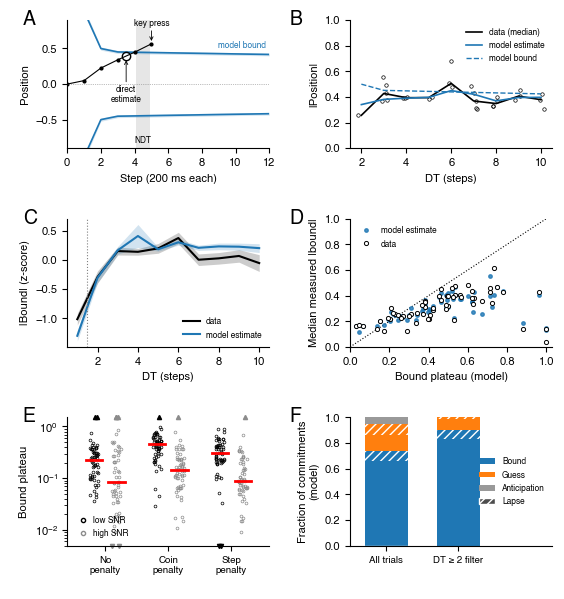

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03.pdf (+ .png)


In [4]:
CM = 1 / 2.54
FS = 8
plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})
MODEL = 'tab:blue'
GR = (0.8, 0.8, 0.8)

fig = plt.figure(figsize=(14 * CM, 15 * CM))
gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.55, wspace=0.4, left=0.1, right=0.98, bottom=0.07, top=0.96)
ax_A, ax_B, ax_C, ax_D, ax_E, ax_F = (fig.add_subplot(gs[r, c]) for r in range(3) for c in range(2))

# A: one example trial: positions, direct estimate, NDT, key press, the subject's fitted bound.
fe = fits_b.loc[EXAMPLE_SUBJECT]
ex = _measured(real_b[real_b.subject_index == EXAMPLE_SUBJECT], 2)
cand = ex[ex.DT.between(4, 6) & (ex.correct == 1)]
trial = cand.iloc[(cand.abs_bound - ex.abs_bound.median()).abs().argsort()].iloc[0]  # typical bound, mid DT
x = np.asarray(trial.steps, float)
steps = np.arange(0, 13)
theta = bound_time_course(fe, np.maximum(steps, 1))
q = scipy.stats.gamma.ppf([0.25, 0.75], a=1 / fe.bound_cv ** 2, scale=fe.bound_cv ** 2)
for sgn in (1, -1):
    ax_A.fill_between(steps, sgn * theta * q[0], sgn * theta * q[1], color=MODEL, alpha=0.2, lw=0)
    ax_A.plot(steps, sgn * theta, color=MODEL, lw=1.2)
dt, rt_step = int(trial.DT), len(x) - 1
ax_A.axvspan(dt + 0.1, rt_step - 0.1, color='0.9', lw=0, zorder=0)
ax_A.plot(np.arange(len(x)), x, 'k.-', lw=0.8, ms=4)
ax_A.plot(dt - 0.5, trial.bound, 'o', mfc='none', mec='k', ms=6, mew=1.0)
ax_A.axhline(0, color='0.5', lw=0.5, ls=':')
ax_A.annotate('direct\nestimate', (dt - 0.5, trial.bound - 0.06), (dt - 0.5, trial.bound - 0.4), fontsize=6,
              ha='center', va='top', arrowprops=dict(arrowstyle='->', lw=0.6, shrinkA=0, shrinkB=0))
ax_A.text((dt + rt_step) / 2, -0.82, 'NDT', fontsize=6, ha='center')
# Vertical arrow from above, so the pointer can't be mistaken for another step of the trace.
ax_A.annotate('key press', (rt_step, x[-1] + 0.04), (rt_step, x[-1] + 0.25), fontsize=6, ha='center',
              arrowprops=dict(arrowstyle='->', lw=0.6, shrinkA=0, shrinkB=0))
ax_A.text(11.8, theta[-1] + 0.06, 'model bound', color=MODEL, fontsize=6, ha='right', va='bottom')
ax_A.set_xlim(0, 12)
ax_A.set_ylim(-0.9, 0.9)
ax_A.set_xlabel('Step (200 ms each)')
ax_A.set_ylabel('Position')
print(f'A: subject {EXAMPLE_SUBJECT}, trial {int(trial.trial_number)}: RT {int(trial.RT)}, DT {dt}, '
      f'direct estimate {trial.bound:.3f}; plateau {fe.bound_scale:.3f}, knee {fe.knee:.2f}, '
      f'h(1) {np.exp(fe.log_h_start):.2f}, bound CV {fe.bound_cv:.3f}')

# B: example subject, measured |bound| vs. DT, with the model's measured and actual bound.
ex_sim = _measured(sim_b[sim_b.subject_index == EXAMPLE_SUBJECT], 2)
dts_b = DTS[1:]
jitter = np.random.default_rng(0).uniform(-0.15, 0.15, len(ex))
ax_B.plot(ex.DT + jitter, ex.abs_bound, 'o', ms=2.5, mfc='none', mec='k', mew=0.5)
ax_B.plot(dts_b, ex.groupby('DT').abs_bound.median().reindex(dts_b), 'k-', lw=1.2, label='data (median)')
ax_B.plot(dts_b, ex_sim.groupby('DT').abs_bound.median().reindex(dts_b), '-', color=MODEL, lw=1.2,
          label='model estimate')
ax_B.plot(dts_b, bound_time_course(fe, dts_b), '--', color=MODEL, lw=1, label='model bound')
ax_B.set_xlim(1.5, 10.5)
ax_B.set_ylim(0, 1)
ax_B.set_xlabel('DT (steps)')
ax_B.set_ylabel('|Position|')
ax_B.legend(fontsize=6, frameon=False, loc='upper right')

# C: all subjects, z-scored measured |bound| vs. DT.
for z, color, label in ((z_real, 'k', 'data'), (z_sim, MODEL, 'model estimate')):
    m, e = z.mean(), z.sem()
    ax_C.fill_between(DTS, m - e, m + e, color=color, alpha=0.2, lw=0)
    ax_C.plot(DTS, m, '-', color=color, lw=1.5, label=label)
ax_C.axvline(1.5, color='0.5', ls=':', lw=0.8)
ax_C.set_xlim(0.5, 10.5)
ax_C.set_xlabel('DT (steps)')
ax_C.set_ylabel('|Bound| (z-score)')
ax_C.legend(fontsize=6, frameon=False, loc='lower right')

# D: per-subject median measured |bound| vs. fitted plateau.
D_MAX = 1.0
off = med.plateau > D_MAX
ax_D.plot([0, D_MAX], [0, D_MAX], 'k:', lw=0.8)
ax_D.plot(med.plateau.clip(upper=D_MAX), med.model, 'o', color=MODEL, ms=2.5, alpha=0.8, label='model estimate')
ax_D.plot(med.plateau.clip(upper=D_MAX), med.data, 'ko', mfc='w', ms=3, mew=0.7, label='data')
ax_D.set_xlim(0, D_MAX * 1.03)
ax_D.set_ylim(0, D_MAX)
ax_D.set_xlabel('Bound plateau (model)')
ax_D.set_ylabel('Median measured |bound|')
ax_D.legend(fontsize=6, frameon=False, loc='upper left')
print(f'D: {int(off.sum())} subject(s) with plateau > {D_MAX} drawn at the edge: '
      f'{med.plateau[off].round(2).to_dict()}')

# E: plateau per subject in every OL block (log scale; reward condition x SNR).
E_GROUPS = [('B1', 'B4'), ('B2', 'B5'), ('B3', 'B6')]
E_LABELS = ['No\npenalty', 'Coin\npenalty', 'Step\npenalty']
# Plateaus at the fit limits (0.002 or 2.0, within 2%) are not bound estimates: at the upper limit
# the bound is never what triggers a commit (guess rate >= 0.5 per step, often lapse = 1), at the
# lower limit any movement does. They are drawn as triangles at the axis edges and left out of
# the medians (reported below).
PLATEAU_LIMITS = (0.002, 2.0)
E_YLIM = (0.005, 1.5)
plateau = fits.pivot(index='subject_index', columns='group', values='bound_scale')
at_limit = (plateau <= PLATEAU_LIMITS[0] * 1.02) | (plateau >= PLATEAU_LIMITS[1] * 0.98)
rng_e = np.random.default_rng(1)
for gi, pair in enumerate(E_GROUPS):
    for si, (block, color) in enumerate(zip(pair, ('k', '0.55'))):
        xpos = gi + (si - 0.5) * 0.36
        v = plateau[block].dropna()
        lim = at_limit[block].reindex(v.index)
        jit = xpos + rng_e.uniform(-0.07, 0.07, len(v))
        ax_E.plot(jit[~lim], v[~lim], 'o', ms=2, mfc='none', mec=color, mew=0.5)
        hi, lo = lim & (v > 1), lim & (v < 1)
        ax_E.plot(jit[hi], np.full(hi.sum(), E_YLIM[1]), '^', ms=3, mfc=color, mec=color, clip_on=False)
        ax_E.plot(jit[lo], np.full(lo.sum(), E_YLIM[0]), 'v', ms=3, mfc=color, mec=color, clip_on=False)
        ax_E.plot([xpos - 0.13, xpos + 0.13], [v[~lim].median()] * 2, 'r-', lw=2)
ax_E.set_yscale('log')
ax_E.set_ylim(*E_YLIM)
ax_E.set_xticks(range(3))
ax_E.set_xticklabels(E_LABELS, fontsize=7)
ax_E.set_xlim(-0.6, 2.6)
ax_E.set_ylabel('Bound plateau')
ax_E.plot([], [], 'o', ms=3, mfc='none', mec='k', label='low SNR')
ax_E.plot([], [], 'o', ms=3, mfc='none', mec='0.55', label='high SNR')
ax_E.legend(fontsize=6, frameon=False, loc='lower left', handletextpad=0.2)
print('E: median plateau per block (excluding fits at a limit):', plateau.where(~at_limit).median().round(3).to_dict())
print('E: fits at a plateau limit, per block (upper / lower):',
      {b: (int((at_limit[b] & (plateau[b] > 1)).sum()), int((at_limit[b] & (plateau[b] < 1)).sum()))
       for b in plateau.columns})

# F: sources of commitments (simulated ground truth); hatching = lapse (random choice).
SRC_COLORS = {'bound': MODEL, 'guess': 'tab:orange', 'anticipation': '0.6'}
for xi, (label, s) in enumerate(src.items()):
    bottom = 0.0
    for k in SOURCES:
        h = s.loc[k, 'fraction']
        ax_F.bar(xi, h, bottom=bottom, color=SRC_COLORS[k], width=0.6, lw=0)
        hl = h * s.loc[k, 'of which lapse']
        ax_F.bar(xi, hl, bottom=bottom + h - hl, color='none', edgecolor='w', hatch='////', width=0.6, lw=0)
        bottom += h
for k in SOURCES:
    ax_F.bar(0, 0, color=SRC_COLORS[k], label=k.capitalize())
ax_F.bar(0, 0, color='0.3', edgecolor='w', hatch='////', label='Lapse')
ax_F.set_xticks([0, 1])
ax_F.set_xticklabels(list(src), fontsize=7)
ax_F.set_xlim(-0.5, 2.3)
ax_F.set_ylim(0, 1)
ax_F.set_ylabel('Fraction of commitments\n(model)')
ax_F.legend(fontsize=6, frameon=False, loc='center right')

for ax, label in zip((ax_A, ax_B, ax_C, ax_D, ax_E, ax_F), 'ABCDEF'):
    ax.spines[['top', 'right']].set_visible(False)
    add_panel_label(ax, label, dx=-0.22 if label in 'ACE' else -0.3)

out = FIGURES_DIR / 'Figure03.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')

## Interpretation

(Filled in after review.)